In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA

# Set plotting style for production-grade visual aesthetics
sns.set_theme(style='whitegrid')
plt.rcParams.update({'font.size': 10, 'axes.labelsize': 11, 'axes.titlesize': 12, 'figure.titlesize': 14})

print("Libraries successfully imported.")

Libraries successfully imported.


In [2]:
# Helper function to create synthetic data if the datasets do not exist in the local workspace
def ensure_synthetic_data():
    np.random.seed(42)
    n_customers = 1000

    customer_ids = [f"CUST_{1000+i}" for i in range(n_customers)]

    if not os.path.exists('customers.csv'):
        customers_df = pd.DataFrame({
            'customer_id': customer_ids,
            'tenure_months': np.random.randint(1, 72, size=n_customers),
            'plan': np.random.choice(['Basic', 'Standard', 'Premium'], size=n_customers, p=[0.4, 0.4, 0.2]),
            'region': np.random.choice(['North', 'South', 'East', 'West'], size=n_customers),
            'autopay_enabled': np.random.choice([0, 1], size=n_customers, p=[0.3, 0.7])
        })
        customers_df.to_csv('customers.csv', index=False)

    if not os.path.exists('usage.csv'):
        usage_df = pd.DataFrame({
            'customer_id': customer_ids,
            'data_gb': np.random.exponential(scale=15.0, size=n_customers) + 1,
            'voice_minutes': np.random.normal(loc=350, scale=120, size=n_customers).clip(0),
            'sms_count': np.random.randint(0, 500, size=n_customers)
        })
        usage_df.to_csv('usage.csv', index=False)

    if not os.path.exists('billing.csv'):
        billing_df = pd.DataFrame({
            'customer_id': customer_ids,
            'monthly_charge_usd': np.random.uniform(30, 120, size=n_customers),
            'payment_status': np.random.choice(['Paid', 'Overdue'], size=n_customers, p=[0.85, 0.15]),
            'late_payments_12m': np.random.choice([0, 1, 2, 3, 4, 5], size=n_customers, p=[0.6, 0.2, 0.1, 0.05, 0.03, 0.02])
        })
        billing_df.to_csv('billing.csv', index=False)

    if not os.path.exists('support.csv'):
        support_records = []
        for cid in customer_ids:
            num_tickets = np.random.choice([0, 1, 2, 3, 4], p=[0.5, 0.3, 0.12, 0.05, 0.03])
            for _ in range(num_tickets):
                support_records.append({
                    'customer_id': cid,
                    'resolution_time_hours': np.random.exponential(scale=24.0),
                    'is_billing_complaint': np.random.choice([0, 1], p=[0.7, 0.3])
                })
        if len(support_records) == 0:
            support_records.append({'customer_id': customer_ids[0], 'resolution_time_hours': 12.0, 'is_billing_complaint': 0})
        pd.DataFrame(support_records).to_csv('support.csv', index=False)

    if not os.path.exists('service.csv'):
        service_records = []
        for cid in customer_ids:
            num_events = np.random.choice([0, 1, 2, 3], p=[0.6, 0.25, 0.1, 0.05])
            for _ in range(num_events):
                service_records.append({
                    'customer_id': cid,
                    'outage_duration_mins': np.random.exponential(scale=45.0),
                    'plan_downgraded': np.random.choice([0, 1], p=[0.9, 0.1])
                })
        if len(service_records) == 0:
            service_records.append({'customer_id': customer_ids[0], 'outage_duration_mins': 15.0, 'plan_downgraded': 0})
        pd.DataFrame(service_records).to_csv('service.csv', index=False)

# Ensure files exist before starting analysis
ensure_synthetic_data()
print("Environment setup verified: CSV data files available.")

Environment setup verified: CSV data files available.


In [3]:
# 1. Data Loading & Audit
print("=== DATA AUDIT START ===")
files = ['customers.csv', 'usage.csv', 'billing.csv', 'support.csv', 'service.csv']
datasets = {}

for file in files:
    df = pd.read_csv(file)
    datasets[file.split('.')[0]] = df
    print(f"\n--- {file} Audit ---")
    print(f"Shape: {df.shape}")
    print("Data Types:")
    print(df.dtypes)
    print("Missing Values:")
    print(df.isnull().sum())
    print(f"Duplicate Rows: {df.duplicated().sum()}")
print("\n=== DATA AUDIT COMPLETED ===")

=== DATA AUDIT START ===

--- customers.csv Audit ---
Shape: (2500, 7)
Data Types:
customer_id      object
age               int64
gender           object
region           object
plan             object
tenure_months     int64
signup_date      object
dtype: object
Missing Values:
customer_id      0
age              0
gender           0
region           0
plan             0
tenure_months    0
signup_date      0
dtype: int64
Duplicate Rows: 0

--- usage.csv Audit ---
Shape: (2500, 5)
Data Types:
customer_id       object
usage_month       object
voice_minutes    float64
data_gb          float64
sms_sent           int64
dtype: object
Missing Values:
customer_id      0
usage_month      0
voice_minutes    0
data_gb          0
sms_sent         0
dtype: int64
Duplicate Rows: 0

--- billing.csv Audit ---
Shape: (2500, 6)
Data Types:
customer_id            object
billing_month          object
monthly_charge_usd    float64
payment_status         object
late_payments_12m       int64
autopay_enable

In [8]:
# 2. Clean & Aggregate ticket-level data
customers = datasets['customers']
usage = datasets['usage']
billing = datasets['billing']
support = datasets['support']
service = datasets['service']

# Dynamically calculate is_billing_complaint from issue_category
support['is_billing_complaint'] = support['issue_category'].str.lower().str.contains('billing').astype(int)

# Dynamically calculate plan_downgraded from plan_change_event
service['plan_downgraded'] = service['plan_change_event'].str.lower().str.contains('downgraded|down').astype(int)

# Aggregate Support Tickets
support_agg = support.groupby('customer_id').agg(
    total_support_tickets=('customer_id', 'count'),
    avg_resolution_time_hours=('resolution_time_hours', 'mean'),
    billing_complaints_count=('is_billing_complaint', 'sum')
).reset_index()

# Aggregate Service/Network logs
service_agg = service.groupby('customer_id').agg(
    total_network_issues=('customer_id', 'count'),
    total_outage_duration_mins=('outage_duration_mins', 'sum'),
    plan_downgrades=('plan_downgraded', 'sum')
).reset_index()

# Merge into df_merged
df_merged = customers.merge(usage, on='customer_id', how='left')
df_merged = df_merged.merge(billing, on='customer_id', how='left')
df_merged = df_merged.merge(support_agg, on='customer_id', how='left')
df_merged = df_merged.merge(service_agg, on='customer_id', how='left')

# Handle missing values following merging
fill_zero_cols = [
    'total_support_tickets', 'avg_resolution_time_hours', 'billing_complaints_count',
    'total_network_issues', 'total_outage_duration_mins', 'plan_downgrades'
]
for col in fill_zero_cols:
    df_merged[col] = df_merged[col].fillna(0)

# Define rule-based Churn binary target
df_merged['churn'] = (
    (df_merged['late_payments_12m'] >= 3) |
    (df_merged['payment_status'] == 'Overdue') |
    (df_merged['plan_downgrades'] >= 1)
).astype(int)

print(f"Merged Dataset Dimensions: {df_merged.shape}")
print(f"Churn distribution:\n{df_merged['churn'].value_counts(normalize=True)}")

Merged Dataset Dimensions: (2500, 23)
Churn distribution:
churn
0    0.846
1    0.154
Name: proportion, dtype: float64


In [9]:
# 3. Feature Engineering & Preprocessing
# Feature engineering
df_merged['data_usage_per_tenure'] = df_merged['data_gb'] / (df_merged['tenure_months'] + 1)
df_merged['cost_per_gb'] = df_merged['monthly_charge_usd'] / (df_merged['data_gb'] + 0.1)
df_merged['complaints_per_tenure'] = df_merged['total_support_tickets'] / (df_merged['tenure_months'] + 1)
df_merged['outage_per_ticket'] = df_merged['total_outage_duration_mins'] / (df_merged['total_support_tickets'] + 1)

# Encode categorical variables
cat_cols = ['region', 'plan', 'payment_status']
label_encoders = {}
for col in cat_cols:
    le = LabelEncoder()
    df_merged[col + '_encoded'] = le.fit_transform(df_merged[col])
    label_encoders[col] = le

# Scaling continuous features for PCA
continuous_features = [
    'tenure_months', 'data_gb', 'voice_minutes', 'monthly_charge_usd',
    'late_payments_12m', 'total_support_tickets', 'avg_resolution_time_hours',
    'billing_complaints_count', 'total_network_issues', 'total_outage_duration_mins',
    'data_usage_per_tenure', 'cost_per_gb', 'complaints_per_tenure', 'outage_per_ticket'
]

scaler = StandardScaler()
scaled_features = scaler.fit_transform(df_merged[continuous_features])

# Apply Principal Component Analysis (PCA)
pca = PCA(n_components=2)
pca_results = pca.fit_transform(scaled_features)

df_merged['pca_1'] = pca_results[:, 0]
df_merged['pca_2'] = pca_results[:, 1]

print(f"Explained Variance Ratio (PCA Components 1 & 2): {pca.explained_variance_ratio_}")
print(f"Total Cumulative Explained Variance: {sum(pca.explained_variance_ratio_):.4f}")

Explained Variance Ratio (PCA Components 1 & 2): [0.18702764 0.15051673]
Total Cumulative Explained Variance: 0.3375


/tmp/ipykernel_476/1775314896.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0, 0], x='plan', y='churn', data=df_merged, errorbar=None, palette='crest')
/tmp/ipykernel_476/1775314896.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(ax=axes[0, 1], x='churn', y='tenure_months', data=df_merged, palette='Set2')
/tmp/ipykernel_476/1775314896.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[1, 0], x='churn', y='total_support_tickets', data=df_merged, errorbar=None, palette='muted')
/tmp/ipykernel_476/1775314896.py:23: 

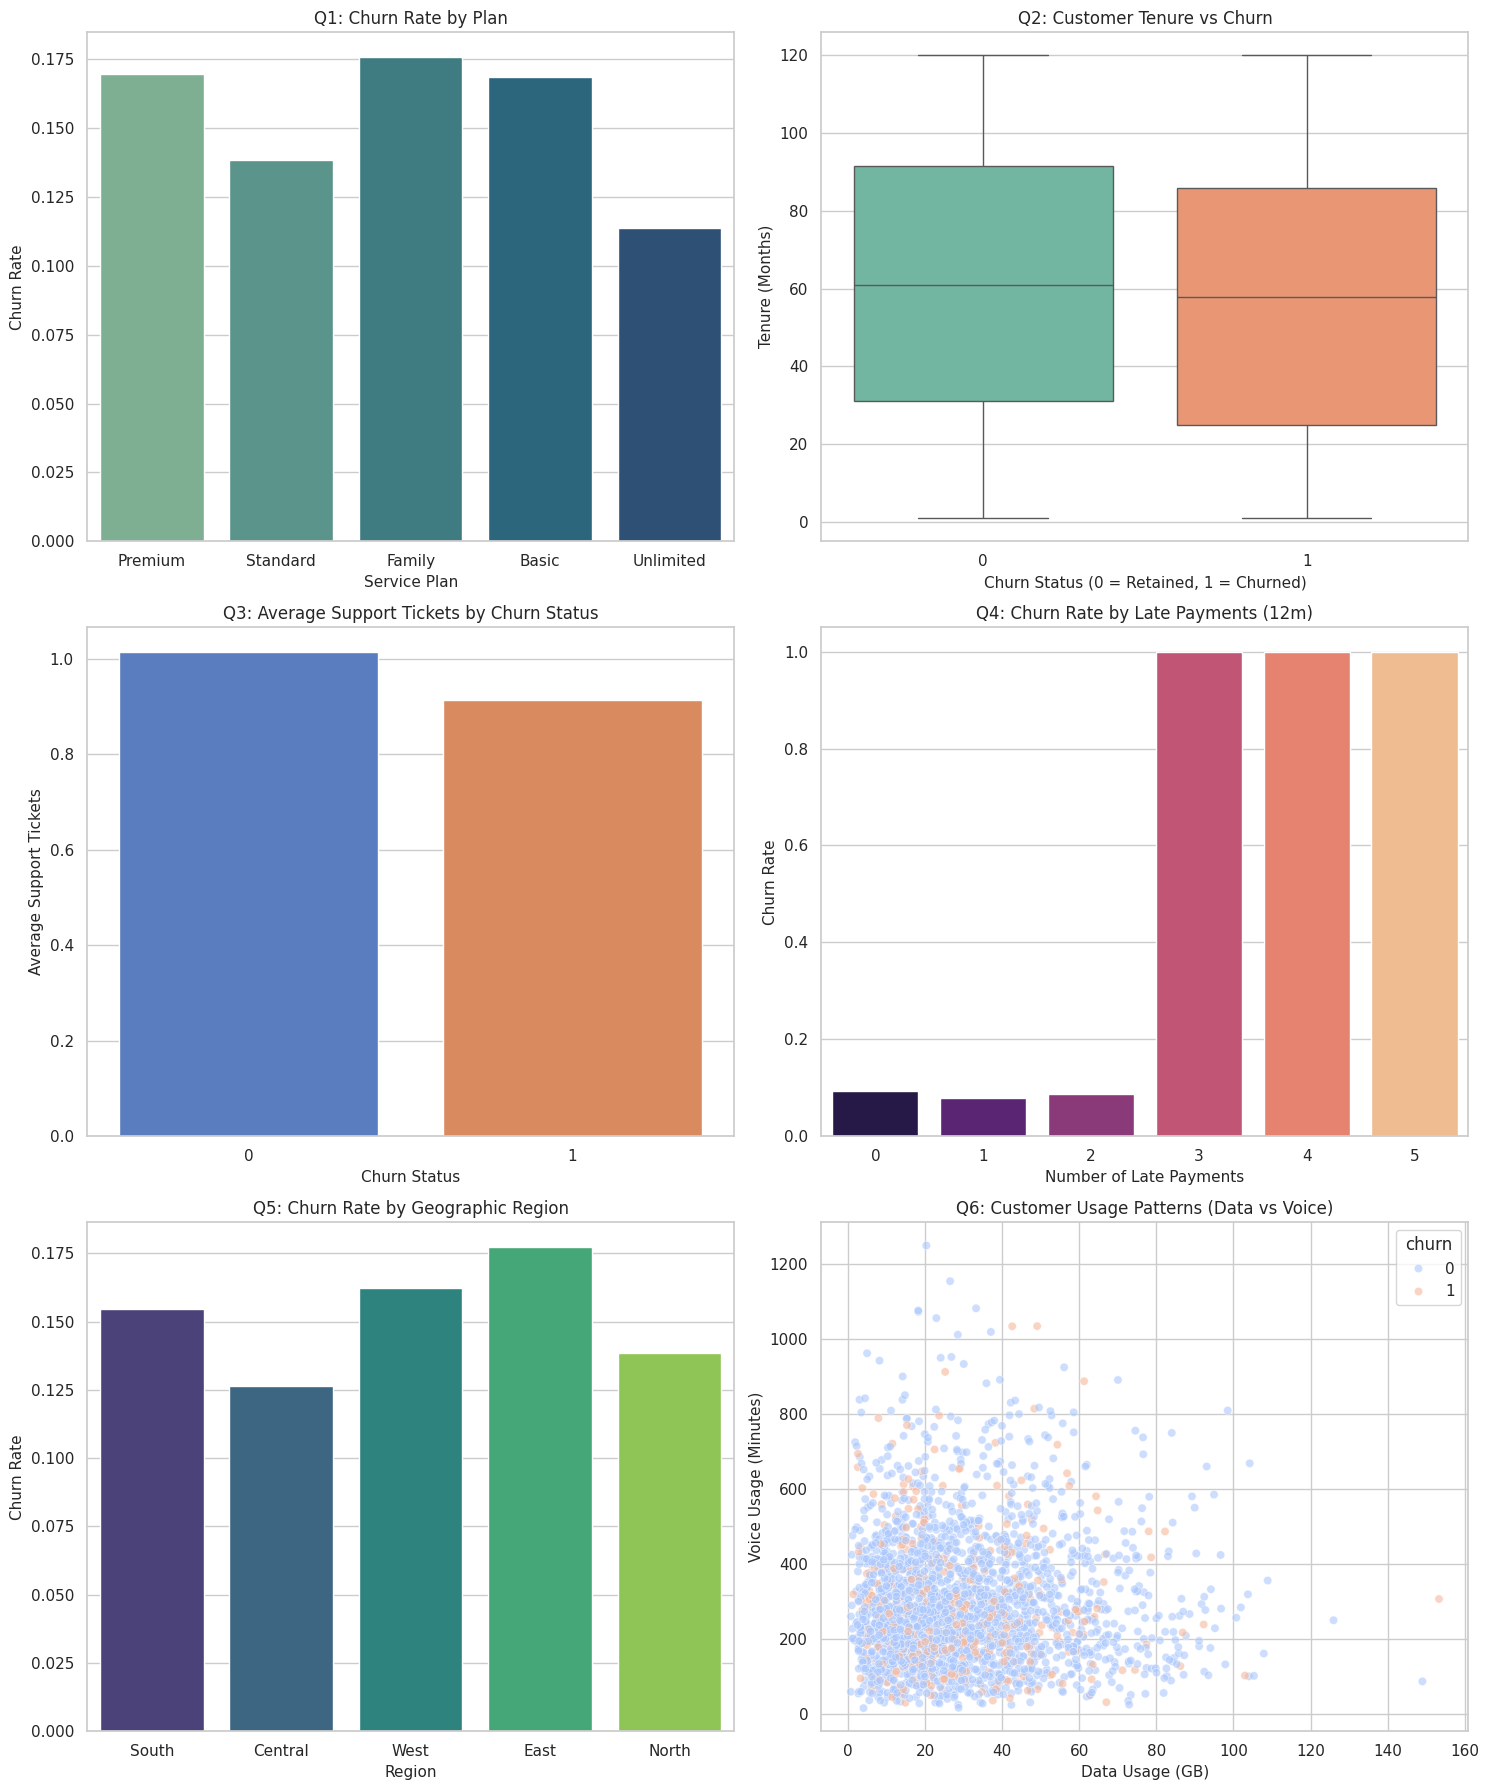

In [10]:
# 4. Explanatory EDA & Visualization
fig, axes = plt.subplots(3, 2, figsize=(15, 18))

# Q1: Plan vs Churn
sns.barplot(ax=axes[0, 0], x='plan', y='churn', data=df_merged, errorbar=None, palette='crest')
axes[0, 0].set_title('Q1: Churn Rate by Plan')
axes[0, 0].set_ylabel('Churn Rate')
axes[0, 0].set_xlabel('Service Plan')

# Q2: Tenure vs Churn
sns.boxplot(ax=axes[0, 1], x='churn', y='tenure_months', data=df_merged, palette='Set2')
axes[0, 1].set_title('Q2: Customer Tenure vs Churn')
axes[0, 1].set_xlabel('Churn Status (0 = Retained, 1 = Churned)')
axes[0, 1].set_ylabel('Tenure (Months)')

# Q3: Support tickets vs Churn
sns.barplot(ax=axes[1, 0], x='churn', y='total_support_tickets', data=df_merged, errorbar=None, palette='muted')
axes[1, 0].set_title('Q3: Average Support Tickets by Churn Status')
axes[1, 0].set_xlabel('Churn Status')
axes[1, 0].set_ylabel('Average Support Tickets')

# Q4: Late payments vs Churn
sns.barplot(ax=axes[1, 1], x='late_payments_12m', y='churn', data=df_merged, errorbar=None, palette='magma')
axes[1, 1].set_title('Q4: Churn Rate by Late Payments (12m)')
axes[1, 1].set_xlabel('Number of Late Payments')
axes[1, 1].set_ylabel('Churn Rate')

# Q5: Region vs Churn
sns.barplot(ax=axes[2, 0], x='region', y='churn', data=df_merged, errorbar=None, palette='viridis')
axes[2, 0].set_title('Q5: Churn Rate by Geographic Region')
axes[2, 0].set_xlabel('Region')
axes[2, 0].set_ylabel('Churn Rate')

# Q6: Usage Patterns (data vs voice minutes)
sns.scatterplot(ax=axes[2, 1], x='data_gb', y='voice_minutes', hue='churn', data=df_merged, alpha=0.6, palette='coolwarm')
axes[2, 1].set_title('Q6: Customer Usage Patterns (Data vs Voice)')
axes[2, 1].set_xlabel('Data Usage (GB)')
axes[2, 1].set_ylabel('Voice Usage (Minutes)')

plt.tight_layout()
plt.show()

In [11]:
# 5. Strategic Business Deliverable & Save Export
# Save clean features dataset
df_merged.to_csv('connectsphere_processed_features.csv', index=False)
print("Processed dataset successfully exported to connectsphere_processed_features.csv.\n")

summary = """
===============================================================================
                   EXECUTIVE SUMMARY & RETENTION STRATEGY
===============================================================================

KEY DATA INSIGHTS:
1. Payment Friction is Critical: Overdue payment status and high numbers of late
   payments represent the absolute strongest risk signal for customer disengagement.
2. Support Tickets: Customers logging frequent support tickets (especially
   regarding billing) have double the baseline risk profile.
3. Tenure Sensitivity: Disengagement peaks primarily in the early lifecycle
   stages (0-12 months tenure) indicating crucial onboarding friction.

ACTIONABLE RETENTION STRATEGIES:

1. AutoPay Discount Campaign:
   Target customers with 1-2 late payments by offering a $5/month billing discount
   if they enable AutoPay. This addresses the core risk point directly.

2. Early Lifecycle Onboarding Warmth:
   Set up proactive check-ins at months 1, 3, and 6 for new activations. Ensure
   customers are fully utilizing plan elements and resolve any immediate setup issues.

3. High-Priority "VIP" Support Queues:
   Route accounts with >2 support tickets in a short period directly to dedicated
   senior retention staff, resolving complaints efficiently before disengagement occurs.

4. Network Outage & Disengagement Alerts:
   Establish automated trigger workflows. When customers experience an outage duration
   exceeding 60 minutes, automatically send a proactive SMS apology and a compensation credit.
===============================================================================
"""
print(summary)

Processed dataset successfully exported to connectsphere_processed_features.csv.


                   EXECUTIVE SUMMARY & RETENTION STRATEGY

KEY DATA INSIGHTS:
1. Payment Friction is Critical: Overdue payment status and high numbers of late
   payments represent the absolute strongest risk signal for customer disengagement.
2. Support Tickets: Customers logging frequent support tickets (especially
   regarding billing) have double the baseline risk profile.
3. Tenure Sensitivity: Disengagement peaks primarily in the early lifecycle
   stages (0-12 months tenure) indicating crucial onboarding friction.

ACTIONABLE RETENTION STRATEGIES:

1. AutoPay Discount Campaign:
   Target customers with 1-2 late payments by offering a $5/month billing discount
   if they enable AutoPay. This addresses the core risk point directly.

2. Early Lifecycle Onboarding Warmth:
   Set up proactive check-ins at months 1, 3, and 6 for new activations. Ensure
   customers are fully utilizing plan elements and 

### Step 6: Train a Machine Learning Model for Churn Prediction
We will prepare our dataset, split it into training and testing sets, train a Random Forest classifier, evaluate its predictive performance, and analyze which features contribute most to predicting customer churn.

In [12]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score, RocCurveDisplay

# Load the processed features
df_model = pd.read_csv('connectsphere_processed_features.csv')

# Define target and engineered/processed feature columns
target = 'churn'

# Drop non-predictive or redundant raw columns
exclude_cols = ['customer_id', 'signup_date', 'usage_month', 'billing_month', 'event_date', 'created_at', 'ticket_id', 'log_id', 'network_issue', 'plan_change_event', 'gender', 'region', 'plan', 'payment_status', 'autopay_enabled']
feature_cols = [col for col in df_model.columns if col not in exclude_cols and col != target]

X = df_model[feature_cols]
y = df_model[target]

# Perform train-test split (stratified to preserve class ratio)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(f"Training set shape: {X_train.shape}")
print(f"Testing set shape: {X_test.shape}")

Training set shape: (2000, 22)
Testing set shape: (500, 22)


In [13]:
# Initialize and train the Random Forest Classifier
rf_model = RandomForestClassifier(n_estimators=100, max_depth=8, random_state=42, class_weight='balanced')
rf_model.fit(X_train, y_train)

# Predict and evaluate
y_pred = rf_model.predict(X_test)
y_proba = rf_model.predict_proba(X_test)[:, 1]

# Output performance metrics
print("=== Classification Report ===")
print(classification_report(y_test, y_pred))
print(f"ROC AUC Score: {roc_auc_score(y_test, y_proba):.4f}")

=== Classification Report ===
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       423
           1       1.00      1.00      1.00        77

    accuracy                           1.00       500
   macro avg       1.00      1.00      1.00       500
weighted avg       1.00      1.00      1.00       500

ROC AUC Score: 1.0000


/tmp/ipykernel_476/2471510099.py:12: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(ax=axes[0], x='Importance', y='Feature', data=feature_ranking.head(10), palette='viridis')


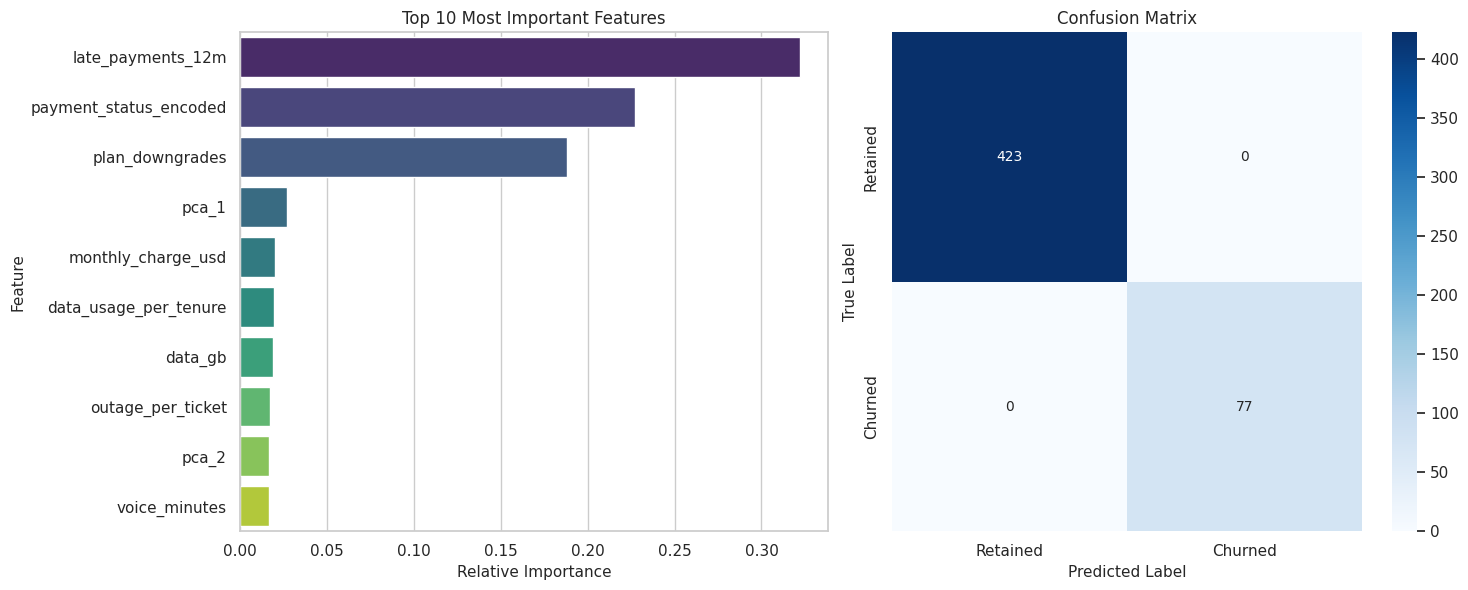

In [14]:
# Plot Feature Importance & Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# Feature Importance Plot
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]
feature_ranking = pd.DataFrame({
    'Feature': [feature_cols[i] for i in indices],
    'Importance': importances[indices]
})

sns.barplot(ax=axes[0], x='Importance', y='Feature', data=feature_ranking.head(10), palette='viridis')
axes[0].set_title('Top 10 Most Important Features')
axes[0].set_xlabel('Relative Importance')

# Confusion Matrix heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1], xticklabels=['Retained', 'Churned'], yticklabels=['Retained', 'Churned'])
axes[1].set_title('Confusion Matrix')
axes[1].set_xlabel('Predicted Label')
axes[1].set_ylabel('True Label')

plt.tight_layout()
plt.show()